# Rough notebook: Weikun daily features

Playground only. Reads Weikun's compressed feature table.

A `.csv.gz` is a normal CSV that was compressed to save space. Pandas opens it with `read_csv`. You do not unzip it first.

Run this notebook from the project folder (the folder that contains `Dhruvesh` and `Weikun`), or from `Dhruvesh`. Both path checks below work.

In [1]:
from pathlib import Path

import pandas as pd

here = Path.cwd()
candidates = [
    here / "Weikun" / "nj_daily_features.csv.gz",
    here.parent / "Weikun" / "nj_daily_features.csv.gz",
]
path = next(p for p in candidates if p.is_file())
print("Reading:", path.resolve())

# Keep ZIP codes as text so 07001 stays 07001.
panel = pd.read_csv(
    path,
    dtype={"zip": "string", "state": "string"},
    parse_dates=["date"],
)

print(panel.shape)
print(panel.date.min().date(), "to", panel.date.max().date())
print(panel.zip.nunique(), "ZIPs")
panel.head()

Reading: /Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Weikun/nj_daily_features.csv.gz
(873678, 50)
2020-01-01 to 2023-12-31
598 ZIPs


,state,zip,date,onset_day_of_week,onset_day_name,onset_record_count,unique_person_zip_onset_count,zero_filled_no_observed_onset_record,surveillance_coverage_confirmed,cases_today,...,internal_jobs,external_inbound_share_nj_network,external_outbound_share_nj_network,case_rate_today_per_100k,case_rate_7d_per_100k,case_rate_14d_per_100k,nj_covid_pressure_7d,pressure_source_weight_coverage_nj_7d,nj_covid_pressure_14d,pressure_source_weight_coverage_nj_14d
0,NJ,07001,2020-01-01,3,Wednesday,0,0,True,False,0,...,250,0.975815,0.96063,0.0,NaN,NaN,NaN,0.0,NaN,0.0
1,NJ,07001,2020-01-02,4,Thursday,0,0,True,False,0,...,250,0.975815,0.96063,0.0,NaN,NaN,NaN,0.0,NaN,0.0
2,NJ,07001,2020-01-03,5,Friday,0,0,True,False,0,...,250,0.975815,0.96063,0.0,NaN,NaN,NaN,0.0,NaN,0.0
3,NJ,07001,2020-01-04,6,Saturday,0,0,True,False,0,...,250,0.975815,0.96063,0.0,NaN,NaN,NaN,0.0,NaN,0.0
4,NJ,07001,2020-01-05,7,Sunday,0,0,True,False,0,...,250,0.975815,0.96063,0.0,NaN,NaN,NaN,0.0,NaN,0.0


In [2]:
# Column names
list(panel.columns)

['state',
 'zip',
 'date',
 'onset_day_of_week',
 'onset_day_name',
 'onset_record_count',
 'unique_person_zip_onset_count',
 'zero_filled_no_observed_onset_record',
 'surveillance_coverage_confirmed',
 'cases_today',
 'day_of_week',
 'month',
 'zero_record_rule_confirmed_by_user',
 'cases_lag_1',
 'cases_lag_7',
 'cases_lag_14',
 'cases_sum_7d',
 'cases_mean_7d',
 'case_std_7d',
 'cases_sum_14d',
 'cases_mean_14d',
 'case_std_14d',
 'week_over_week_change',
 'case_velocity',
 'case_acceleration',
 'case_jerk',
 'days_since_last_observed_case',
 'population',
 'land_area_sq_km',
 'population_density_per_sq_km',
 'population_period',
 'area_vintage',
 'valid_population_denominator',
 'zip_zcta_mapping_status',
 'commuting_year',
 'commuting_job_type',
 'resident_jobs_nj_network',
 'workplace_jobs_nj_network',
 'inbound_jobs_external_nj',
 'outbound_jobs_external_nj',
 'internal_jobs',
 'external_inbound_share_nj_network',
 'external_outbound_share_nj_network',
 'case_rate_today_per_100k

In [3]:
# One ZIP over time. Change the string to explore another ZIP.
zipcode = "08901"
one = panel.loc[panel.zip.eq(zipcode)].sort_values("date")
one[[
    "zip", "date", "cases_today",
    "cases_sum_7d", "case_rate_7d_per_100k",
    "nj_covid_pressure_7d", "population",
]].head(20)

,zip,date,cases_today,cases_sum_7d,case_rate_7d_per_100k,nj_covid_pressure_7d,population
869295,08901,2020-01-01,0,NaN,NaN,NaN,57257
869296,08901,2020-01-02,0,NaN,NaN,NaN,57257
869297,08901,2020-01-03,0,NaN,NaN,NaN,57257
869298,08901,2020-01-04,0,NaN,NaN,NaN,57257
869299,08901,2020-01-05,0,NaN,NaN,NaN,57257
869300,08901,2020-01-06,0,NaN,NaN,NaN,57257
869301,08901,2020-01-07,0,0.0,0.0,NaN,57257
869302,08901,2020-01-08,0,0.0,0.0,NaN,57257
869303,08901,2020-01-09,0,0.0,0.0,NaN,57257
869304,08901,2020-01-10,0,0.0,0.0,NaN,57257


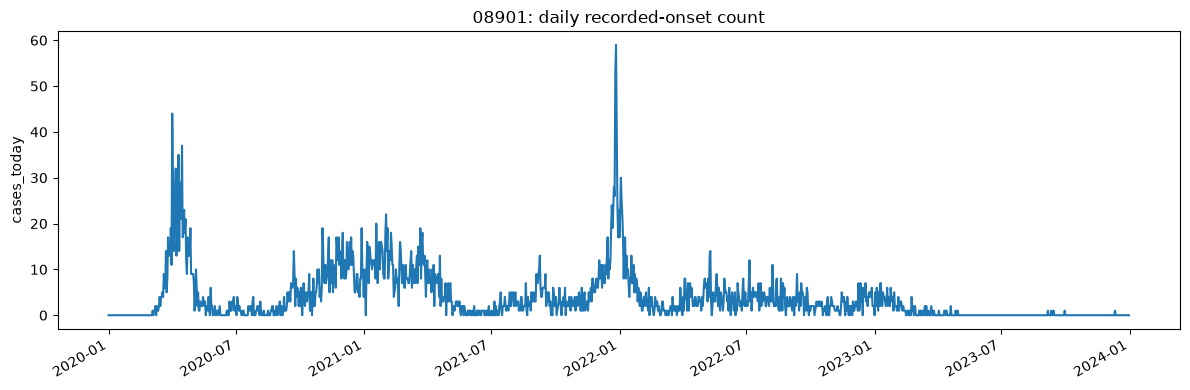

In [4]:
# Quick plot for that ZIP
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(one.date, one.cases_today)
ax.set_title(f"{zipcode}: daily recorded-onset count")
ax.set_ylabel("cases_today")
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()

In [5]:
# Your sandbox: add cells below and try filters, groupbys, more plots.
panel[["cases_today", "population", "nj_covid_pressure_7d"]].describe()

,cases_today,population,nj_covid_pressure_7d
count,873678.000000,873678.000000,672210.000000
mean,1.190821,15441.511706,55.824290
std,2.721932,15693.134364,62.133928
min,0.000000,0.000000,0.000000
25%,0.000000,4213.000000,7.700365
50%,0.000000,10128.000000,37.110328
75%,1.000000,21940.000000,80.780149
max,100.000000,130352.000000,686.648767
